In [ ]:
# ============================================================
# ANÁLISIS DE BURSTINESS — RECLUTAMIENTO ILÍCITO DE MENORES
# Colombia 1990–2017
# Fuente: Proyecto conjunto JEP-CEV-HRDAG (verdata v2)
# ============================================================

# ============================================================
# 0. INSTALACIÓN DE DEPENDENCIAS
# ============================================================
# Ejecutar en Colab antes de correr el script:
!pip install geopandas unidecode powerlaw --quiet

# ============================================================
# 1. IMPORTS
# ============================================================
import io
import os
import zipfile

import geopandas as gpd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import files
from unidecode import unidecode

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 235.8/235.8 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 192.0/192.0 kB 6.9 MB/s eta 0:00:00


In [ ]:
# ============================================================
# 2. CARGA DE ARCHIVOS
# Sube en este orden cuando aparezca el botón:
#   (1) ZIP con las 100 réplicas de reclutamiento (verdata v2)
#   (2) Excel de población DANE
#   (3) Todos los archivos del shapefile (.shp, .dbf, .shx, etc.)
# ============================================================

print("=" * 60)
print("PASO 1: Sube el ZIP con las 100 réplicas de reclutamiento")
print("=" * 60)
uploaded_zip = files.upload()
nombre_zip   = list(uploaded_zip.keys())[0]

print("\n" + "=" * 60)
print("PASO 2: Sube el Excel de población DANE")
print("=" * 60)
uploaded_pop = files.upload()
nombre_pop   = list(uploaded_pop.keys())[0]

print("\n" + "=" * 60)
print("PASO 3: Sube todos los archivos del shapefile de Colombia")
print("=" * 60)
uploaded_shp = files.upload()

PASO 1: Sube el ZIP con las 100 réplicas de reclutamiento


Saving Reclutamiento.csv.zip to Reclutamiento.csv.zip

PASO 2: Sube el Excel de población DANE


Saving Poblaciones Totales Departamentos.xlsx to Poblaciones Totales Departamentos.xlsx

PASO 3: Sube todos los archivos del shapefile de Colombia


Saving gadm41_COL_1.shp to gadm41_COL_1.shp
Saving gadm41_COL_1.shx to gadm41_COL_1.shx
Saving gadm41_COL_1.cpg to gadm41_COL_1.cpg
Saving gadm41_COL_1.dbf to gadm41_COL_1.dbf
Saving gadm41_COL_1.prj to gadm41_COL_1.prj


In [ ]:
# ============================================================
# 3. IDENTIFICAR REGISTROS CON MES IMPUTADO
# Comparando yymm_hecho en las 100 réplicas
# ============================================================
print("\nIdentificando registros con mes imputado...")

with zipfile.ZipFile(io.BytesIO(uploaded_zip[nombre_zip]), 'r') as z:
    contenido = z.namelist()

archivos = sorted([
    f for f in contenido
    if f.endswith('.csv') and not f.endswith('/')
])
print(f"Réplicas disponibles: {len(archivos)}")

fechas_por_id = {}

with zipfile.ZipFile(io.BytesIO(uploaded_zip[nombre_zip]), 'r') as z:
    for i, archivo in enumerate(archivos):
        with z.open(archivo) as f:
            r = pd.read_csv(f,
                            usecols=['match_group_id', 'yymm_hecho'],
                            dtype={'match_group_id': str})
        for _, row in r.iterrows():
            mid = row['match_group_id']
            val = row['yymm_hecho']
            if mid not in fechas_por_id:
                fechas_por_id[mid] = set()
            fechas_por_id[mid].add(val)

        if (i + 1) % 10 == 0:
            print(f"  Procesadas {i+1}/100 réplicas...")

ids_inestables = {
    mid for mid, vals in fechas_por_id.items()
    if len(vals) > 1
}

print(f"\nRegistros con mes imputado (inestable): {len(ids_inestables)}")
print(f"Porcentaje del total                   : "
      f"{len(ids_inestables)/len(fechas_por_id)*100:.2f}%")

# Diagnóstico de inestabilidad
n_valores = {mid: len(vals) for mid, vals in fechas_por_id.items()
             if len(vals) > 1}
conteo = pd.Series(n_valores).value_counts().sort_index()
print("Distribución de valores únicos de yymm_hecho en inestables:")
for n_val, freq in conteo.items():
    print(f"  {n_val} valores distintos : {freq} registros")

# ============================================================
# 4. CARGA DE LA RÉPLICA 1 Y FILTRADO
# ============================================================
print("\nCargando réplica R1...")

# Identificar el archivo R1 dentro del ZIP
archivo_r1 = next(
    (f for f in archivos if 'R1.csv' in f or '-R1.csv' in f), archivos[0]
)

with zipfile.ZipFile(io.BytesIO(uploaded_zip[nombre_zip]), 'r') as z:
    with z.open(archivo_r1) as f:
        df = pd.read_csv(f, dtype={'dept_code_hecho': str,
                                   'muni_code_hecho': str})

print(f"Registros totales cargados : {len(df):,}")

# Estandarizar código de departamento (zfill=2)
df['dept_code_hecho'] = df['dept_code_hecho'].str.zfill(2)

# Excluir registros con mes imputado
df_filtrado = df[~df['match_group_id'].isin(ids_inestables)].copy()

# Excluir registros sin departamento o sin fecha
n_antes = len(df_filtrado)
df_filtrado = df_filtrado[
    df_filtrado['dept_code_hecho'].notna() &
    df_filtrado['yymm_hecho'].notna()
].copy()

print(f"Registros eliminados (mes imputado)    : {len(df) - len(df_filtrado):,}")
print(f"Registros finales                      : {len(df_filtrado):,}")

# Extraer año y mes
df_filtrado['anio'] = df_filtrado['yymm_hecho'] // 100
df_filtrado['mes']  = df_filtrado['yymm_hecho'] % 100

# Delimitar al rango temporal 1990–2017
df_filtrado = df_filtrado[df_filtrado['anio'].between(1990, 2017)].copy()

print(f"Registros en rango 1990–2017           : {len(df_filtrado):,}")
print(f"Departamentos únicos                   : "
      f"{df_filtrado['dept_code_hecho'].nunique()}")

# ============================================================
# 5. CARGA DE POBLACIÓN DANE
# ============================================================
pop = pd.read_excel(
    io.BytesIO(uploaded_pop[nombre_pop]),
    dtype={'DP': str}
)
pop['DP'] = pop['DP'].str.zfill(2)
pop = pop[pop['Año'].between(1990, 2017)].copy()

# Verificar match
deptos_recl = set(df_filtrado['dept_code_hecho'].unique())
deptos_pop  = set(pop['DP'].unique())

sin_match_recl = deptos_recl - deptos_pop
sin_match_pop  = deptos_pop  - deptos_recl

print("\nDepartamentos en reclutamiento SIN match en población:")
print(sin_match_recl if sin_match_recl else "  Ninguno ✓")
print("Departamentos en población SIN match en reclutamiento:")
print(sin_match_pop if sin_match_pop else "  Ninguno ✓")

# ============================================================
# 6. CONSTRUCCIÓN DE LA GRILLA TEMPORAL
# ============================================================
conteo = (
    df_filtrado
    .groupby(['dept_code_hecho', 'anio', 'mes'])
    .size()
    .reset_index(name='reclutados')
)

departamentos = df_filtrado['dept_code_hecho'].unique()
idx = pd.MultiIndex.from_product(
    [departamentos, range(1990, 2018), range(1, 13)],
    names=['dept_code_hecho', 'anio', 'mes']
)

grilla = pd.DataFrame(index=idx).reset_index()
grilla = grilla.merge(conteo, on=['dept_code_hecho', 'anio', 'mes'], how='left')
grilla['reclutados'] = grilla['reclutados'].fillna(0).astype(int)

pop_menores = pop[['DP', 'Año', 'Total (menores)']].copy()
grilla = grilla.merge(
    pop_menores,
    left_on  = ['dept_code_hecho', 'anio'],
    right_on = ['DP', 'Año'],
    how      = 'left'
).drop(columns=['DP', 'Año'])

grilla['Total (menores)'] = grilla.groupby(
    ['dept_code_hecho', 'anio']
)['Total (menores)'].transform('first')

grilla['tasa'] = (
    grilla['reclutados'] / (grilla['Total (menores)'] / 12)
) * 100_000

grilla['fecha'] = pd.to_datetime(
    dict(year=grilla['anio'], month=grilla['mes'], day=1)
)

print(f"\n=== GRILLA TEMPORAL ===")
print(f"Filas totales          : {len(grilla):,}  "
      f"(esperado: {len(departamentos)*28*12:,})")
print(f"Meses con reclutados>0 : {(grilla['reclutados'] > 0).sum():,}")
print(f"Meses con reclutados=0 : {(grilla['reclutados'] == 0).sum():,}")

# ============================================================
# 7. SHAPEFILE Y LOOKUP CÓDIGO DANE
# ============================================================
colombia = gpd.read_file("/content/gadm41_COL_1.shp")

gadm_a_dane_raw = {
    'Amazonas': '91', 'Antioquia': '05', 'Arauca': '81',
    'Atlantico': '08', 'Bolivar': '13', 'Boyaca': '15',
    'Caldas': '17', 'Caqueta': '18', 'Casanare': '85',
    'Cauca': '19', 'Cesar': '20', 'Choco': '27',
    'Cordoba': '23', 'Cundinamarca': '25', 'Guainia': '94',
    'Guaviare': '95', 'Huila': '41', 'La Guajira': '44',
    'Magdalena': '47', 'Meta': '50', 'Narino': '52',
    'Norte De Santander': '54', 'Putumayo': '86', 'Quindio': '63',
    'Risaralda': '66', 'San Andres Y Providencia': '88',
    'Santander': '68', 'Sucre': '70', 'Tolima': '73',
    'Valle Del Cauca': '76', 'Vaupes': '97', 'Vichada': '99',
    'Bogota D.C.': '11',
}

gadm_a_dane_norm = {
    unidecode(k).upper().strip(): v
    for k, v in gadm_a_dane_raw.items()
}

colombia['NAME_norm'] = (
    colombia['NAME_1']
    .apply(lambda x: unidecode(str(x)).upper().strip())
)
colombia['dept_code'] = colombia['NAME_norm'].map(gadm_a_dane_norm)

sin_codigo = colombia[colombia['dept_code'].isna()]['NAME_1'].tolist()
print("\nDepartamentos sin código DANE asignado:")
print(sin_codigo if sin_codigo else "  Ninguno ✓")

# Lookup código → nombre
lookup_nombre = (
    pop[['DP', 'Departamento']]
    .drop_duplicates()
    .set_index('DP')['Departamento']
    .to_dict()
)

# ============================================================
# 8. FUNCIONES DE BURSTING
# ============================================================
def calcular_bursting(serie_reclutados):
    indices_eventos = np.where(serie_reclutados > 0)[0]
    if len(indices_eventos) < 2:
        return None
    iet = np.diff(indices_eventos).astype(float)
    if len(iet) < 2:
        return None
    mu    = iet.mean()
    sigma = iet.std(ddof=1)
    B = (sigma - mu) / (sigma + mu) if (sigma + mu) > 0 else 0
    iet1, iet2 = iet[:-1], iet[1:]
    mu1, mu2   = iet1.mean(), iet2.mean()
    s1, s2     = iet1.std(ddof=1), iet2.std(ddof=1)
    M = np.mean((iet1 - mu1) * (iet2 - mu2)) / (s1 * s2) \
        if s1 > 0 and s2 > 0 else 0.0
    return {
        'B': B, 'M': M,
        'n_eventos': len(indices_eventos),
        'n_iet': len(iet),
        'mu_iet': mu, 'sigma_iet': sigma,
    }

def simular_B_nulo(n_eventos, n_meses=336, n_sim=1000):
    tasa = n_eventos / n_meses
    Bs_nulo = []
    for _ in range(n_sim):
        llegadas = np.random.poisson(tasa, n_meses)
        idx = np.where(llegadas > 0)[0]
        if len(idx) < 2:
            continue
        iet = np.diff(idx).astype(float)
        mu, sigma = iet.mean(), iet.std(ddof=1)
        if (sigma + mu) > 0:
            Bs_nulo.append((sigma - mu) / (sigma + mu))
    return np.percentile(Bs_nulo, 95) if Bs_nulo else np.nan

def cuadrante(row):
    b, m = row['B'], row['M']
    if   b >= 0 and m >= 0: return 'Bursty + Memoria'
    elif b >= 0 and m <  0: return 'Bursty - Memoria'
    elif b <  0 and m >= 0: return 'Regular + Memoria'
    else:                    return 'Regular - Memoria'

# ============================================================
# 9. ANÁLISIS DE BURSTING POR DEPARTAMENTO
# ============================================================
np.random.seed(42)
print("\nCalculando parámetros de bursting...")

resultados = []
for depto in grilla['dept_code_hecho'].unique():
    serie_depto = (
        grilla[grilla['dept_code_hecho'] == depto]
        .sort_values(['anio', 'mes'])['reclutados']
        .values
    )
    res = calcular_bursting(serie_depto)
    if res is None:
        continue
    B_nulo_p95        = simular_B_nulo(res['n_eventos'],
                                        n_meses=len(serie_depto))
    res['B_nulo_p95'] = B_nulo_p95
    res['bursty_sig'] = (res['B'] > 0) & (res['B'] > B_nulo_p95)
    res['dept_code']  = depto
    res['grupo']      = (
        'A (>100)'   if res['n_eventos'] > 100 else
        'B (40-100)' if res['n_eventos'] >= 40 else
        'C (<40)'
    )
    resultados.append(res)

df_burst              = pd.DataFrame(resultados).sort_values('B', ascending=False)
df_burst['departamento'] = df_burst['dept_code'].map(lookup_nombre)

df_resumen            = df_burst.copy()
df_resumen['cuadrante'] = df_resumen.apply(cuadrante, axis=1)

print("\n=== PARÁMETROS DE BURSTING POR DEPARTAMENTO ===\n")
print(df_resumen[[
    'departamento', 'dept_code', 'grupo', 'n_eventos',
    'B', 'M', 'B_nulo_p95', 'bursty_sig', 'mu_iet', 'sigma_iet'
]].to_string(index=False))

print(f"\nDepartamentos bursty significativos : "
      f"{df_resumen['bursty_sig'].sum()} / {len(df_resumen)}")
print(f"B promedio global                   : {df_resumen['B'].mean():.4f}")
print(f"B promedio Grupo A                  : "
      f"{df_resumen[df_resumen['grupo']=='A (>100)']['B'].mean():.4f}")
print(f"M promedio global                   : {df_resumen['M'].mean():.4f}")

print("\n=== DISTRIBUCIÓN POR CUADRANTE ===")
print(df_resumen['cuadrante'].value_counts())

print("\n=== ESTADÍSTICAS POR GRUPO ===")
for grupo in ['A (>100)', 'B (40-100)', 'C (<40)']:
    sub = df_resumen[df_resumen['grupo'] == grupo]
    if len(sub) == 0:
        continue
    print(f"\n{grupo}:")
    print(f"  n departamentos : {len(sub)}")
    print(f"  B promedio      : {sub['B'].mean():.4f} ± {sub['B'].std():.4f}")
    print(f"  M promedio      : {sub['M'].mean():.4f} ± {sub['M'].std():.4f}")
    print(f"  Bursty sig (%)  : {sub['bursty_sig'].mean()*100:.1f}%")
    print(f"  mu_iet promedio : {sub['mu_iet'].mean():.2f} meses")




Identificando registros con mes imputado...
Réplicas disponibles: 100
  Procesadas 10/100 réplicas...
  Procesadas 20/100 réplicas...
  Procesadas 30/100 réplicas...
  Procesadas 40/100 réplicas...
  Procesadas 50/100 réplicas...
  Procesadas 60/100 réplicas...
  Procesadas 70/100 réplicas...
  Procesadas 80/100 réplicas...
  Procesadas 90/100 réplicas...
  Procesadas 100/100 réplicas...

Registros con mes imputado (inestable): 176
Porcentaje del total                   : 0.92%
Distribución de valores únicos de yymm_hecho en inestables:
  12 valores distintos : 176 registros

Cargando réplica R1...
Registros totales cargados : 19,226
Registros eliminados (mes imputado)    : 176
Registros finales                      : 19,050
Registros en rango 1990–2017           : 19,050
Departamentos únicos                   : 32

Departamentos en reclutamiento SIN match en población:
  Ninguno ✓
Departamentos en población SIN match en reclutamiento:
{'88'}

=== GRILLA TEMPORAL ===
Filas totales    

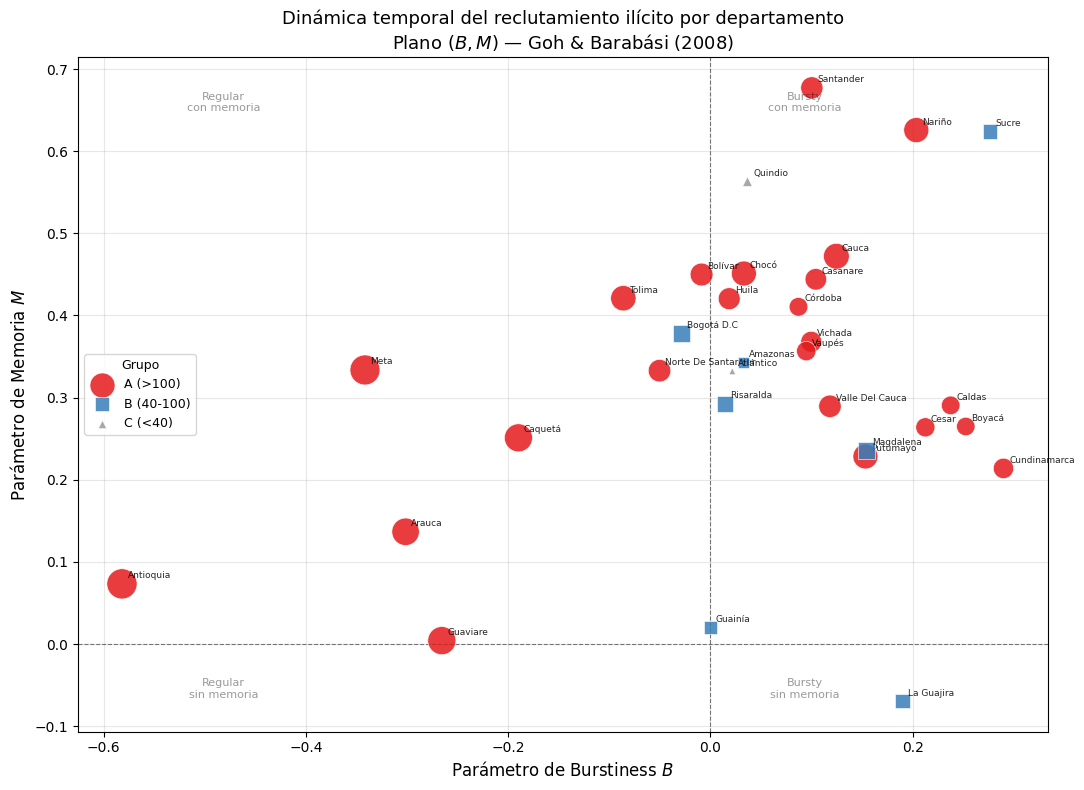

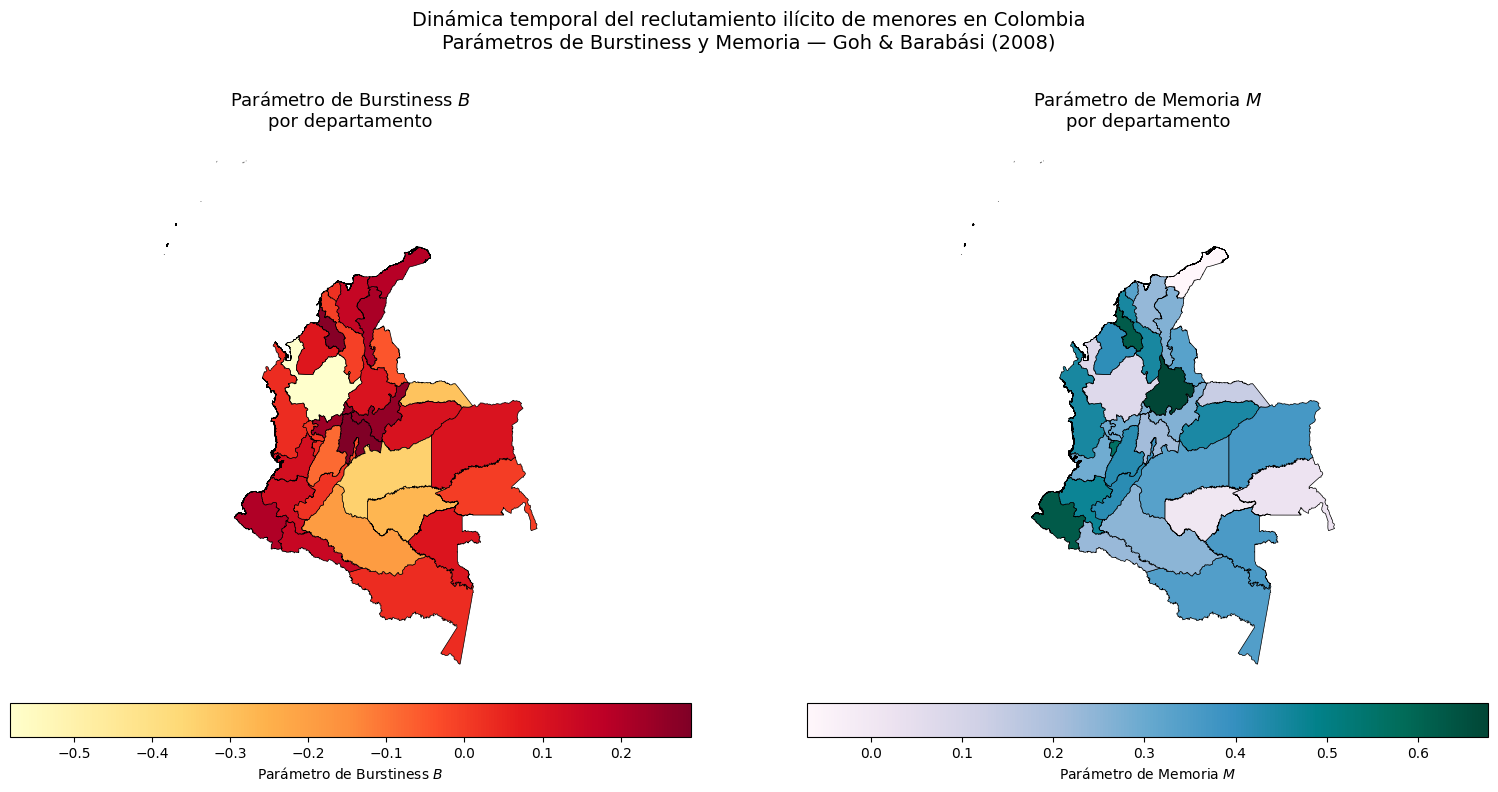


Más bursty  : Cundinamarca (B=0.290, M=0.214)
Menos bursty: Antioquia (B=-0.582, M=0.073)


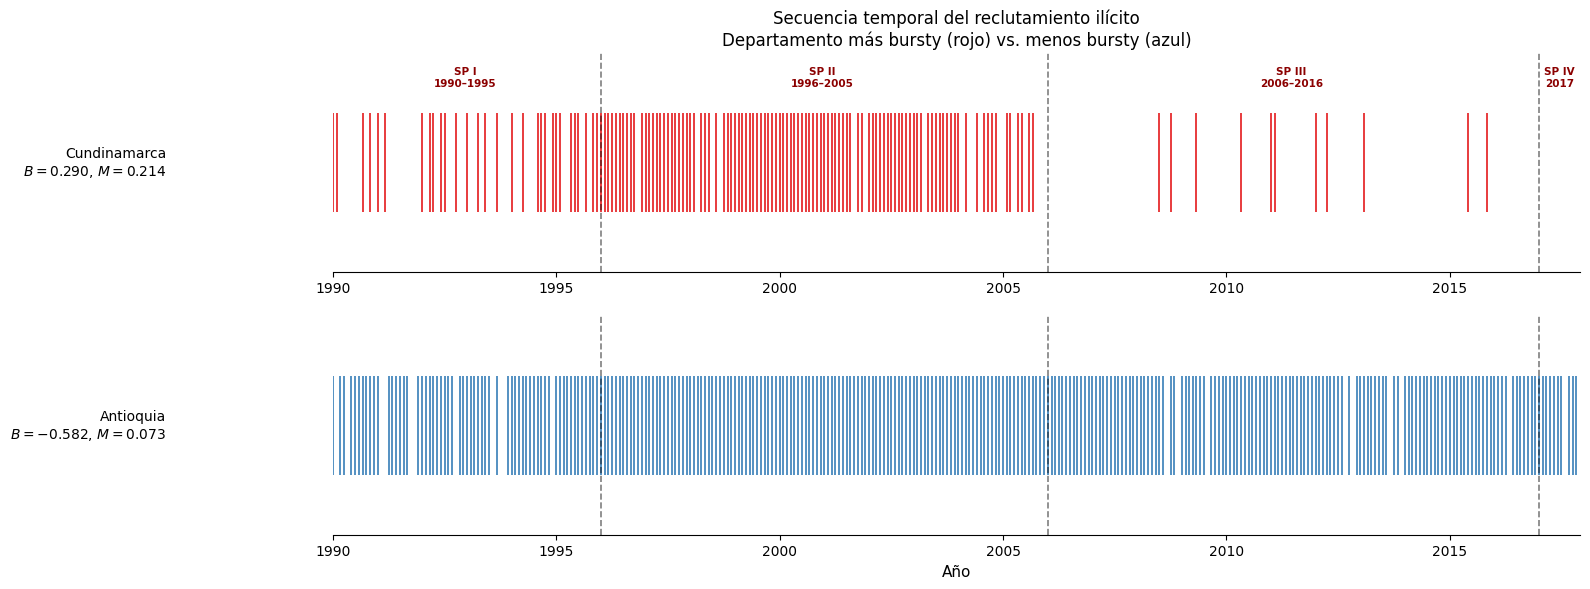

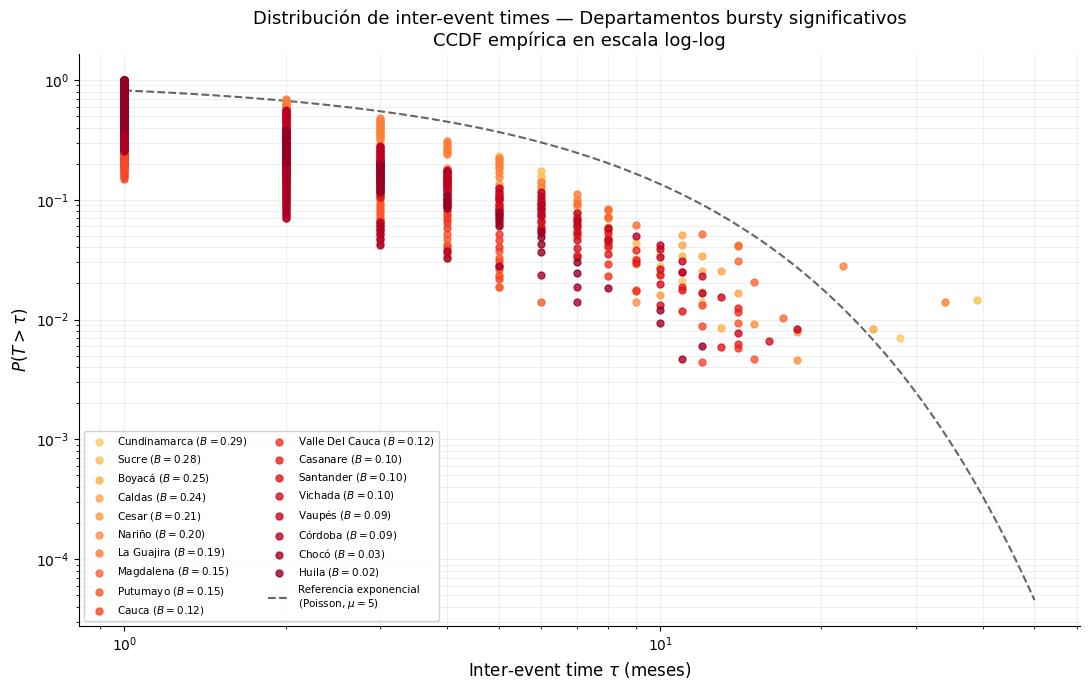

In [ ]:
# ============================================================
# 10. VISUALIZACIONES
# ============================================================
geo_burst = colombia.merge(df_resumen, on='dept_code', how='left')

# --- FIGURA 1: Plano (B, M) ---
fig, ax = plt.subplots(figsize=(11, 8))

colores = {'A (>100)': '#e41a1c', 'B (40-100)': '#377eb8', 'C (<40)': '#999999'}
markers = {'A (>100)': 'o',       'B (40-100)': 's',       'C (<40)': '^'}

for grupo, sub in df_resumen.groupby('grupo'):
    ax.scatter(
        sub['B'], sub['M'],
        c=colores[grupo], marker=markers[grupo],
        s=sub['n_eventos'] * 1.5,
        alpha=0.85, edgecolors='white', linewidths=0.5,
        label=grupo, zorder=3
    )
    for _, row in sub.iterrows():
        ax.annotate(
            str(row['departamento']).title(),
            (row['B'], row['M']),
            fontsize=6.5, alpha=0.85,
            xytext=(4, 4), textcoords='offset points'
        )

ax.axhline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)
ax.axvline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)

kwargs = dict(fontsize=8, alpha=0.4, ha='center')
ax.text(0.75, 0.92, 'Bursty\ncon memoria',  transform=ax.transAxes, **kwargs)
ax.text(0.15, 0.92, 'Regular\ncon memoria', transform=ax.transAxes, **kwargs)
ax.text(0.75, 0.05, 'Bursty\nsin memoria',  transform=ax.transAxes, **kwargs)
ax.text(0.15, 0.05, 'Regular\nsin memoria', transform=ax.transAxes, **kwargs)

ax.set_xlabel('Parámetro de Burstiness $B$', fontsize=12)
ax.set_ylabel('Parámetro de Memoria $M$', fontsize=12)
ax.set_title(
    'Dinámica temporal del reclutamiento ilícito por departamento\n'
    'Plano $(B, M)$ — Goh & Barabási (2008)',
    fontsize=13
)
ax.legend(title='Grupo', fontsize=9, title_fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- FIGURA 2: Mapas B y M ---
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for ax, col, cmap, label in zip(
    axes,
    ['B', 'M'],
    ['YlOrRd', 'PuBuGn'],
    ['Parámetro de Burstiness $B$', 'Parámetro de Memoria $M$']
):
    geo_burst.plot(
        column=col, ax=ax, cmap=cmap, legend=True,
        legend_kwds={
            'label': label, 'orientation': 'horizontal',
            'shrink': 0.7, 'pad': 0.02
        },
        missing_kwds={'color': '#d9d9d9', 'label': 'Sin datos suficientes'},
        edgecolor='black', linewidth=0.5
    )
    ax.set_title(f'{label}\npor departamento', fontsize=13)
    ax.axis('off')

plt.suptitle(
    'Dinámica temporal del reclutamiento ilícito de menores en Colombia\n'
    'Parámetros de Burstiness y Memoria — Goh & Barabási (2008)',
    fontsize=14, y=1.01
)
plt.tight_layout()
plt.show()

# # --- FIGURA 3: Mapa de cuadrantes ---
# fig, ax = plt.subplots(figsize=(10, 12))

# geo_burst[geo_burst['B'].isna()].plot(
#     ax=ax, color='#d9d9d9', edgecolor='white', linewidth=0.5
# )

# colores_cuadrante = {
#     'Bursty + Memoria' : '#e41a1c',
#     'Bursty - Memoria' : '#ff7f00',
#     'Regular + Memoria': '#377eb8',
#     'Regular - Memoria': '#984ea3',
# }

# for cuad, color in colores_cuadrante.items():
#     subset = geo_burst[geo_burst['cuadrante'] == cuad]
#     if len(subset) > 0:
#         subset.plot(ax=ax, color=color, edgecolor='white',
#                     linewidth=0.5, label=cuad)

# geo_burst[geo_burst['bursty_sig'] == True].plot(
#     ax=ax, color='none', edgecolor='black',
#     linewidth=1.8, label='Bursting significativo'
# )

# ax.set_title(
#     'Clasificación dinámica del reclutamiento ilícito\n'
#     'por cuadrante en el plano $(B, M)$',
#     fontsize=13
# )
# ax.legend(loc='lower left', fontsize=9, framealpha=0.9)
# ax.axis('off')
# plt.tight_layout()
# plt.show()

# --- FIGURA 4: Rasterplot más y menos bursty ---
dept_max_B = df_resumen.loc[df_resumen['B'].idxmax(), 'dept_code']
dept_min_B = df_resumen.loc[df_resumen['B'].idxmin(), 'dept_code']

nombre_max = str(lookup_nombre.get(dept_max_B, dept_max_B)).title()
nombre_min = str(lookup_nombre.get(dept_min_B, dept_min_B)).title()
B_max = df_resumen.loc[df_resumen['dept_code'] == dept_max_B, 'B'].values[0]
B_min = df_resumen.loc[df_resumen['dept_code'] == dept_min_B, 'B'].values[0]
M_max = df_resumen.loc[df_resumen['dept_code'] == dept_max_B, 'M'].values[0]
M_min = df_resumen.loc[df_resumen['dept_code'] == dept_min_B, 'M'].values[0]

print(f"\nMás bursty  : {nombre_max} (B={B_max:.3f}, M={M_max:.3f})")
print(f"Menos bursty: {nombre_min} (B={B_min:.3f}, M={M_min:.3f})")

xlim_ini = mdates.date2num(pd.Timestamp('1990-01-01'))
xlim_fin = mdates.date2num(pd.Timestamp('2017-12-01'))
cortes   = [1996, 2006, 2017]

fig, axes = plt.subplots(2, 1, figsize=(16, 6),
                          gridspec_kw={'height_ratios': [1, 1]})

for ax, dept, nombre, B_val, M_val, color in zip(
    axes,
    [dept_max_B, dept_min_B],
    [nombre_max, nombre_min],
    [B_max, B_min], [M_max, M_min],
    ['#e41a1c', '#377eb8']
):
    fechas_depto = (
        grilla[
            (grilla['dept_code_hecho'] == dept) &
            (grilla['reclutados'] > 0)
        ]['fecha'].values
    )
    fechas_num = mdates.date2num(pd.to_datetime(fechas_depto))

    ax.eventplot(fechas_num, orientation='horizontal',
                 lineoffsets=0, linelengths=0.8,
                 linewidths=1.2, colors=color)

    for año_corte in cortes:
        ax.axvline(
            mdates.date2num(pd.Timestamp(f'{año_corte}-01-01')),
            color='black', linewidth=1.2, linestyle='--', alpha=0.5
        )

    ax.set_yticks([])
    ax.set_ylabel(
        f'{nombre}\n$B={B_val:.3f}$, $M={M_val:.3f}$',
        fontsize=10, rotation=0, ha='right', va='center', labelpad=120
    )
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.xaxis.set_major_locator(mdates.YearLocator(5))
    ax.set_xlim(xlim_ini, xlim_fin)
    ax.grid(False)
    for spine in ['top', 'right', 'left']:
        ax.spines[spine].set_visible(False)

    if ax == axes[0]:
        ax.set_title(
            'Secuencia temporal del reclutamiento ilícito\n'
            'Departamento más bursty (rojo) vs. menos bursty (azul)',
            fontsize=12
        )
        for label, ini, fin in zip(
            ['SP I\n1990–1995', 'SP II\n1996–2005',
             'SP III\n2006–2016', 'SP IV\n2017'],
            ['1990-01-01', '1996-01-01', '2006-01-01', '2017-01-01'],
            ['1995-12-01', '2005-12-01', '2016-12-01', '2017-12-01']
        ):
            mid = pd.Timestamp(ini) + (
                pd.Timestamp(fin) - pd.Timestamp(ini)
            ) / 2
            ax.text(
                mdates.date2num(mid), 0.85, label,
                ha='center', fontsize=7.5, color='darkred',
                fontweight='bold', transform=ax.get_xaxis_transform()
            )

axes[-1].set_xlabel('Año', fontsize=11)
plt.tight_layout(h_pad=1.5)
plt.show()

# --- FIGURA 5: CCDF de IETs — departamentos bursty significativos ---
deptos_bursty = (
    df_resumen[df_resumen['bursty_sig'] == True]
    .sort_values('B', ascending=False)['dept_code']
    .tolist()
)

n_bursty = len(deptos_bursty)
cmap_ccdf = plt.cm.YlOrRd(np.linspace(0.3, 0.95, n_bursty))

fig, ax = plt.subplots(figsize=(11, 7))

for i, dept in enumerate(deptos_bursty):
    serie_depto = (
        grilla[grilla['dept_code_hecho'] == dept]
        .sort_values(['anio', 'mes'])['reclutados']
        .values
    )
    idx        = np.where(serie_depto > 0)[0]
    iet        = np.diff(idx).astype(float)
    iet_sorted = np.sort(iet)
    ccdf       = 1 - np.arange(1, len(iet_sorted) + 1) / len(iet_sorted)
    nombre     = str(lookup_nombre.get(dept, dept)).title()
    B_val      = df_resumen.loc[df_resumen['dept_code'] == dept, 'B'].values[0]

    ax.scatter(iet_sorted, ccdf, color=cmap_ccdf[i], s=25, alpha=0.80,
               label=f'{nombre} ($B={B_val:.2f}$)', zorder=3)

tau_ref  = np.linspace(1, 50, 300)
ccdf_exp = np.exp(-tau_ref / 5)
ax.plot(tau_ref, ccdf_exp, color='black', linewidth=1.5,
        linestyle='--', alpha=0.6,
        label='Referencia exponencial\n(Poisson, $\\mu=5$)')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Inter-event time $\\tau$ (meses)', fontsize=12)
ax.set_ylabel('$P(T > \\tau)$', fontsize=12)
ax.set_title(
    'Distribución de inter-event times — Departamentos bursty significativos\n'
    'CCDF empírica en escala log-log',
    fontsize=13
)
ax.legend(fontsize=7.5, loc='lower left', framealpha=0.9, ncol=2)
ax.grid(True, alpha=0.2, which='both')
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()


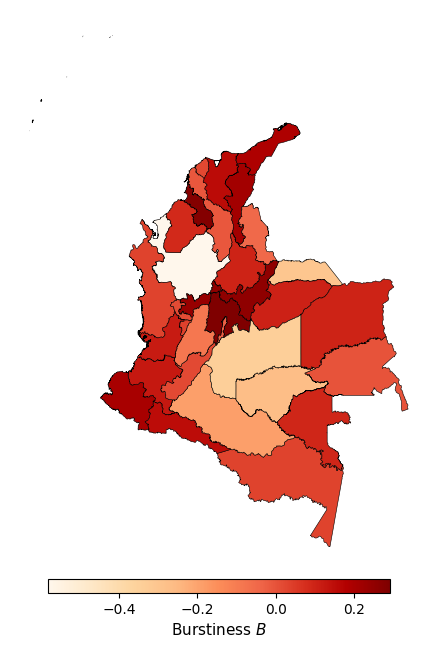

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 7))

geo_burst.plot(
    column='B', ax=ax, cmap='OrRd', legend=True,
    legend_kwds={
        'label': 'Burstiness $B$',
        'orientation': 'horizontal',
        'shrink': 0.6, 'pad': 0.01, 'aspect': 25
    },
    missing_kwds={'color': '#d9d9d9'},
    edgecolor='black', linewidth=0.4
)

ax.axis('off')

# Ajustar tamaño de las etiquetas de la barra de color
cbar_ax = fig.axes[-1]
cbar_ax.tick_params(labelsize=10)
cbar_ax.xaxis.label.set_size(11)

plt.tight_layout()
plt.savefig('mapa_burstiness.png', dpi=300, bbox_inches='tight',
            facecolor='white')
plt.show()

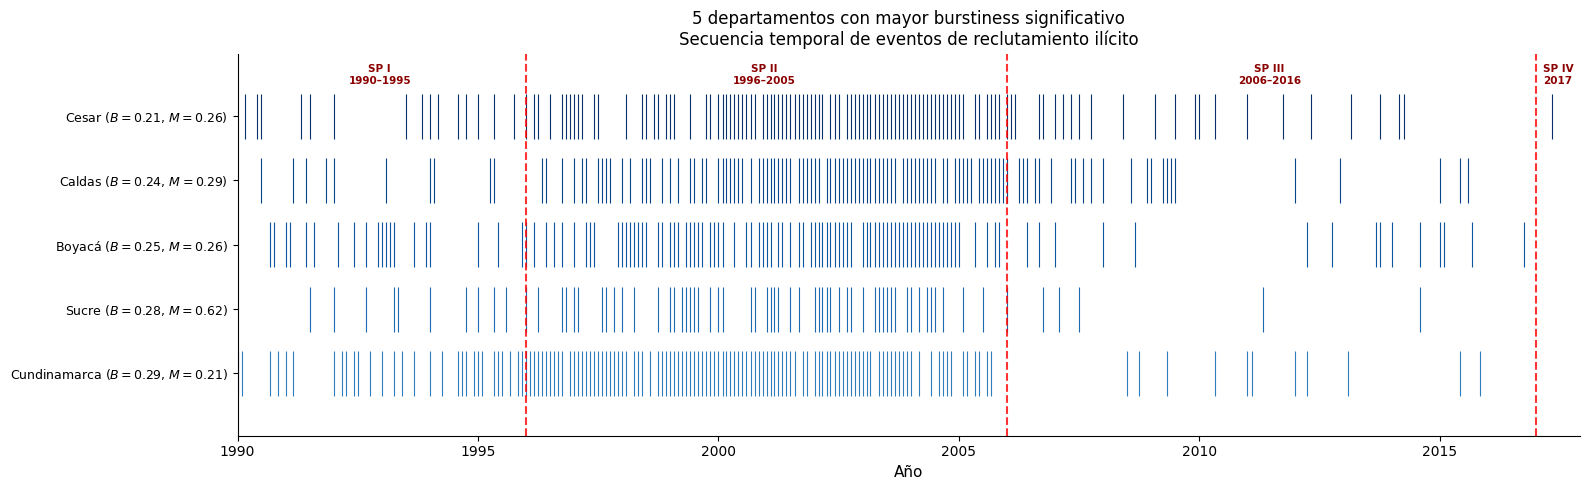

In [ ]:
# ============================================================
# RASTERPLOT: 5 DEPARTAMENTOS MÁS BURSTY
# ============================================================
deptos_top5 = (
    df_resumen[df_resumen['bursty_sig'] == True]
    .sort_values('B', ascending=False)
    .head(5)['dept_code']
    .tolist()
)

n_top5    = len(deptos_top5)
cmap_top5 = plt.cm.Blues(np.linspace(0.7, 1, n_top5))

B_por_depto      = df_resumen.set_index('dept_code')['B']
M_por_depto      = df_resumen.set_index('dept_code')['M']
nombre_por_depto = df_resumen.set_index('dept_code')['departamento']

fig, ax = plt.subplots(figsize=(16, 5))

for i, dept in enumerate(deptos_top5):
    fechas_depto = (
        grilla[
            (grilla['dept_code_hecho'] == dept) &
            (grilla['reclutados'] > 0)
        ]['fecha'].values
    )
    fechas_num = mdates.date2num(pd.to_datetime(fechas_depto))
    ax.eventplot(
        fechas_num, orientation='horizontal',
        lineoffsets=i, linelengths=0.7,
        linewidths=0.8, colors=[cmap_top5[i]]
    )

for año_corte in cortes:
    ax.axvline(
        mdates.date2num(pd.Timestamp(f'{año_corte}-01-01')),
        color='red', linewidth=1.5, linestyle='--', alpha=0.8
    )

ax.set_yticks(range(n_top5))
ax.set_yticklabels(
    [f"{str(nombre_por_depto.get(d, d)).title()} "
     f"($B={B_por_depto[d]:.2f}$, $M={M_por_depto[d]:.2f}$)"
     for d in deptos_top5],
    fontsize=9
)

# Etiquetas sub-periodos
for label, ini, fin in zip(
    ['SP I\n1990–1995', 'SP II\n1996–2005',
     'SP III\n2006–2016', 'SP IV\n2017'],
    ['1990-01-01', '1996-01-01', '2006-01-01', '2017-01-01'],
    ['1995-12-01', '2005-12-01', '2016-12-01', '2017-12-01']
):
    mid = pd.Timestamp(ini) + (
        pd.Timestamp(fin) - pd.Timestamp(ini)
    ) / 2
    ax.text(
        mdates.date2num(mid), n_top5 - 0.5,
        label,
        ha='center', fontsize=7.5, color='darkred',
        fontweight='bold'
        # sin transform: coordenadas de datos en ambos ejes
    )

ax.set_xlim(xlim_ini, xlim_fin)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.set_xlabel('Año', fontsize=11)
ax.set_title(
    '5 departamentos con mayor burstiness significativo\n'
    'Secuencia temporal de eventos de reclutamiento ilícito',
    fontsize=12
)
ax.grid(False)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
# Cambiar el color de las gráficas por colores más contrastantes y hacer la distribución de departamentos bursty. Tomar medida de burstiness a los periodos.

=== COMPARACIÓN B vs An (Kim & Jo 2016) ===

      departamento      grupo  n_eventos         B  B_random_ref  B_bursty_max        An  An_sig
             Sucre B (40-100)         70  0.276471     -0.007143      0.785099  0.333898    True
      Cundinamarca   A (>100)        143  0.289886     -0.003497      0.845158  0.328482    True
            Boyacá   A (>100)        118  0.252585     -0.004237      0.830747  0.289945    True
            Caldas   A (>100)        120  0.237633     -0.004167      0.832056  0.272294    True
             Cesar   A (>100)        127  0.212606     -0.003937      0.836400  0.242426    True
        La Guajira B (40-100)         72  0.189817     -0.006945      0.787824  0.228502    True
            Nariño   A (>100)        217  0.203649     -0.002304      0.872587  0.224164    True
         Magdalena B (40-100)         98  0.154581     -0.005102      0.815649  0.180605    True
          Putumayo   A (>100)        215  0.153339     -0.002326      0.872031  0.

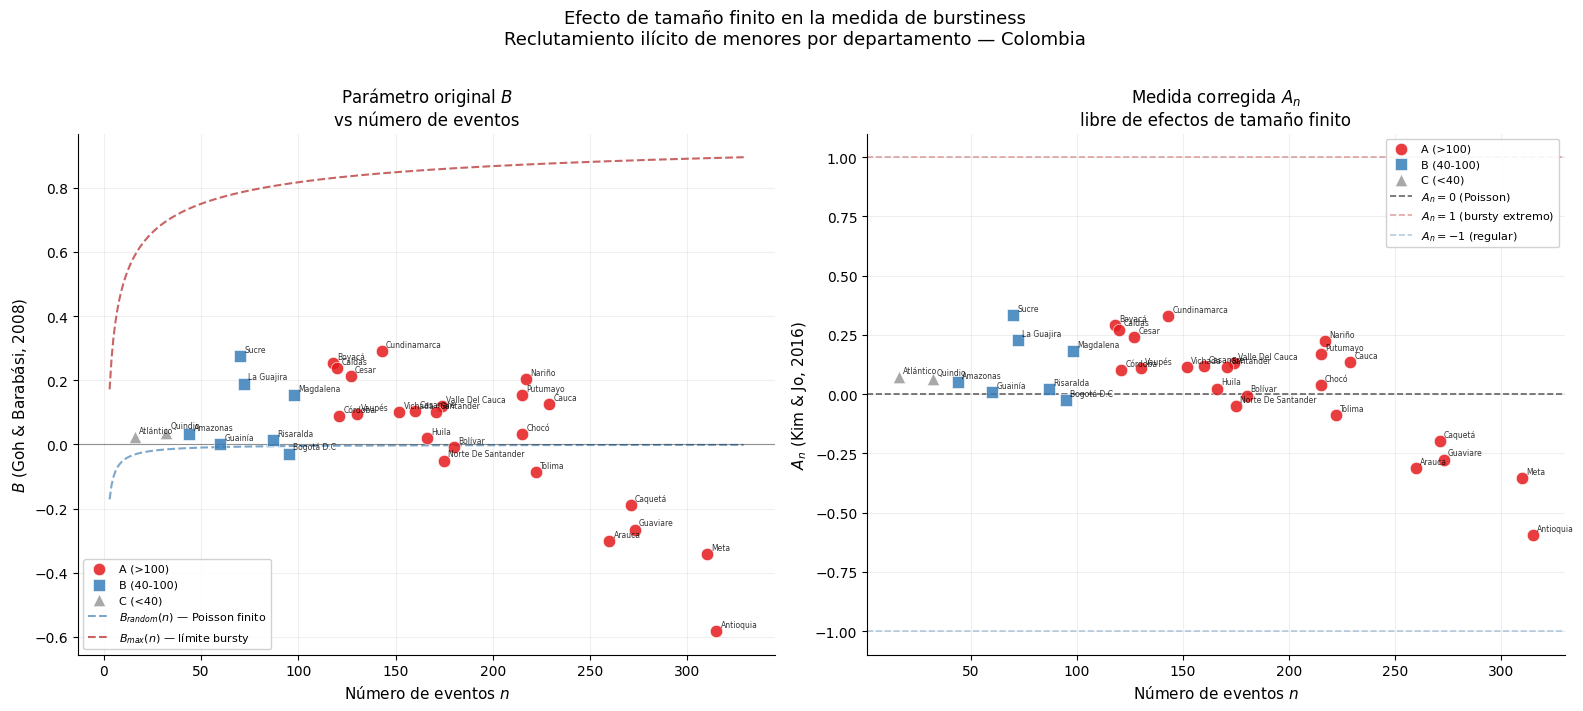

Figura guardada: fig6_B_vs_An_finito.png


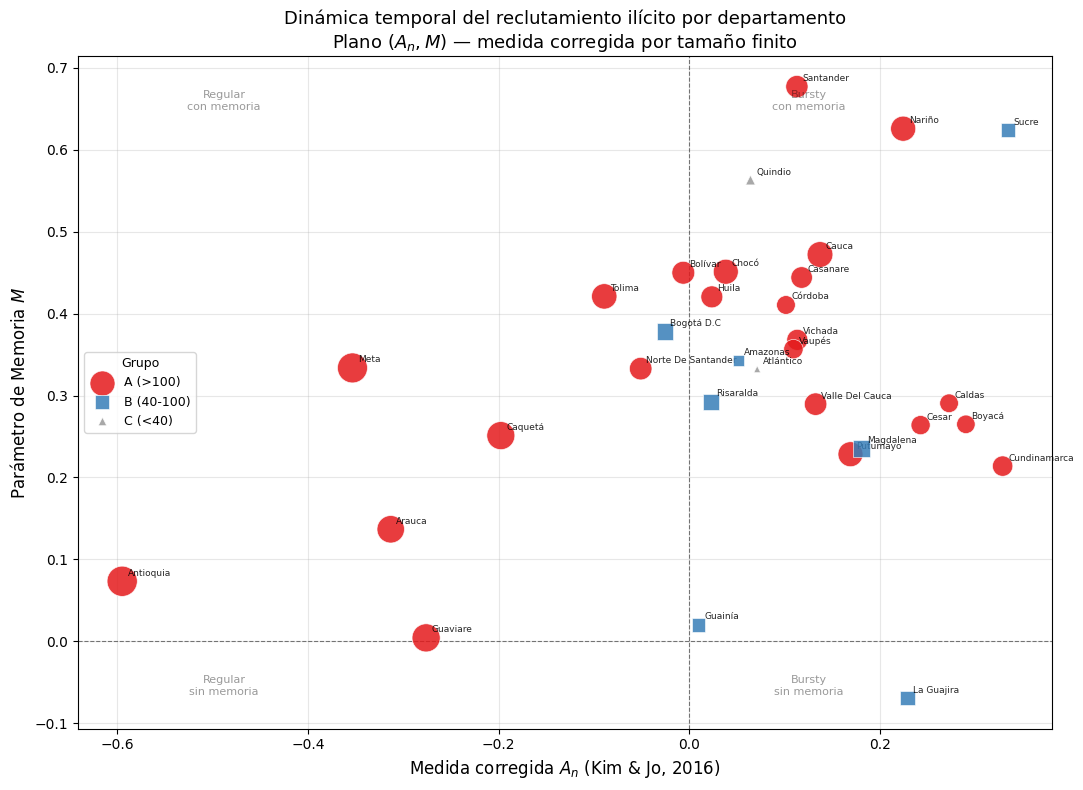

Figura guardada: fig7_plano_An_M.png


In [ ]:
# ============================================================
# MEDIDA DE BURSTINESS CORREGIDA POR TAMAÑO FINITO
# Kim & Jo (2016), Physical Review E 94, 032311
# ============================================================

def calcular_An(r, n):
    """
    Medida alternativa de burstiness corregida por tamaño finito.
    Kim & Jo (2016), Eq. (22).

    Parámetros:
        r : coeficiente de variación (sigma / mu) de los IETs
        n : número de eventos

    Retorna An(r) ∈ [-1, 1] libre de efectos de tamaño finito.
    """
    if n < 2:
        return np.nan
    sqrt_n1 = np.sqrt(n + 1)
    sqrt_n_1 = np.sqrt(n - 1)
    numerador   = sqrt_n1 * r - sqrt_n_1
    denominador = (sqrt_n1 - 2) * r + sqrt_n_1
    return numerador / denominador if denominador != 0 else np.nan

def B_random_finito(n):
    """
    Valor esperado de B bajo Poisson para n eventos finitos.
    Kim & Jo (2016), Eq. (19).
    Sirve como referencia: B > B_random_finito(n) indica burstiness.
    """
    return (np.sqrt(n - 1) - np.sqrt(n + 1)) / \
           (np.sqrt(n - 1) + np.sqrt(n + 1))

def B_bursty_max(n):
    """
    Valor máximo alcanzable de B para n eventos finitos.
    Kim & Jo (2016), Eq. (20).
    """
    return (np.sqrt(n - 1) - 1) / (np.sqrt(n - 1) + 1)

# ============================================================
# AGREGAR An A df_resumen
# ============================================================
def calcular_An_desde_fila(row):
    r = row['sigma_iet'] / row['mu_iet'] if row['mu_iet'] > 0 else 0
    return calcular_An(r, row['n_eventos'])

df_resumen['r']            = df_resumen['sigma_iet'] / df_resumen['mu_iet']
df_resumen['An']           = df_resumen.apply(calcular_An_desde_fila, axis=1)
df_resumen['B_random_ref'] = df_resumen['n_eventos'].apply(B_random_finito)
df_resumen['B_bursty_max'] = df_resumen['n_eventos'].apply(B_bursty_max)

# Significancia corregida: An > 0 equivale a B > B_random_finito(n)
df_resumen['An_sig'] = df_resumen['An'] > 0

print("=== COMPARACIÓN B vs An (Kim & Jo 2016) ===\n")
print(df_resumen[[
    'departamento', 'grupo', 'n_eventos',
    'B', 'B_random_ref', 'B_bursty_max',
    'An', 'An_sig'
]].sort_values('An', ascending=False).to_string(index=False))

print(f"\nDepartamentos con An > 0 (bursty corregido) : "
      f"{df_resumen['An_sig'].sum()} / {len(df_resumen)}")
print(f"Departamentos con B > 0 (original)          : "
      f"{(df_resumen['B'] > 0).sum()} / {len(df_resumen)}")

print("\n=== ESTADÍSTICAS POR GRUPO ===")
for grupo in ['A (>100)', 'B (40-100)', 'C (<40)']:
    sub = df_resumen[df_resumen['grupo'] == grupo]
    if len(sub) == 0:
        continue
    print(f"\n{grupo}  (n_eventos medio: {sub['n_eventos'].mean():.0f})")
    print(f"  B  promedio : {sub['B'].mean():.4f} ± {sub['B'].std():.4f}")
    print(f"  An promedio : {sub['An'].mean():.4f} ± {sub['An'].std():.4f}")
    print(f"  An_sig (%)  : {sub['An_sig'].mean()*100:.1f}%")

# ============================================================
# VISUALIZACIÓN: B vs An por departamento
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

colores = {'A (>100)': '#e41a1c', 'B (40-100)': '#377eb8', 'C (<40)': '#999999'}
markers = {'A (>100)': 'o',       'B (40-100)': 's',       'C (<40)': '^'}

# --- Panel izquierdo: B original ---
ax1 = axes[0]
for grupo, sub in df_resumen.groupby('grupo'):
    ax1.scatter(
        sub['n_eventos'], sub['B'],
        c=colores[grupo], marker=markers[grupo],
        s=80, alpha=0.85, edgecolors='white',
        linewidths=0.5, label=grupo, zorder=3
    )
    for _, row in sub.iterrows():
        ax1.annotate(
            str(row['departamento']).title(),
            (row['n_eventos'], row['B']),
            fontsize=5.5, alpha=0.8,
            xytext=(3, 3), textcoords='offset points'
        )

# Curvas de referencia teóricas
n_range = np.arange(3, 330)
ax1.plot(n_range, [B_random_finito(n) for n in n_range],
         color='steelblue', linewidth=1.5, linestyle='--',
         alpha=0.7, label='$B_{random}(n)$ — Poisson finito')
ax1.plot(n_range, [B_bursty_max(n) for n in n_range],
         color='firebrick', linewidth=1.5, linestyle='--',
         alpha=0.7, label='$B_{max}(n)$ — límite bursty')
ax1.axhline(0, color='black', linewidth=0.8, linestyle='-', alpha=0.4)

ax1.set_xlabel('Número de eventos $n$', fontsize=11)
ax1.set_ylabel('$B$ (Goh & Barabási, 2008)', fontsize=11)
ax1.set_title('Parámetro original $B$\nvs número de eventos',
              fontsize=12)
ax1.legend(fontsize=8, framealpha=0.9)
ax1.grid(True, alpha=0.2)
for spine in ['top', 'right']:
    ax1.spines[spine].set_visible(False)

# --- Panel derecho: An corregido ---
ax2 = axes[1]
for grupo, sub in df_resumen.groupby('grupo'):
    ax2.scatter(
        sub['n_eventos'], sub['An'],
        c=colores[grupo], marker=markers[grupo],
        s=80, alpha=0.85, edgecolors='white',
        linewidths=0.5, label=grupo, zorder=3
    )
    for _, row in sub.iterrows():
        ax2.annotate(
            str(row['departamento']).title(),
            (row['n_eventos'], row['An']),
            fontsize=5.5, alpha=0.8,
            xytext=(3, 3), textcoords='offset points'
        )

ax2.axhline(0, color='black', linewidth=1.2, linestyle='--',
            alpha=0.6, label='$A_n = 0$ (Poisson)')
ax2.axhline(1, color='firebrick', linewidth=1.2, linestyle='--',
            alpha=0.4, label='$A_n = 1$ (bursty extremo)')
ax2.axhline(-1, color='steelblue', linewidth=1.2, linestyle='--',
             alpha=0.4, label='$A_n = -1$ (regular)')

ax2.set_xlabel('Número de eventos $n$', fontsize=11)
ax2.set_ylabel('$A_n$ (Kim & Jo, 2016)', fontsize=11)
ax2.set_title('Medida corregida $A_n$\nlibre de efectos de tamaño finito',
              fontsize=12)
ax2.legend(fontsize=8, framealpha=0.9)
ax2.grid(True, alpha=0.2)
for spine in ['top', 'right']:
    ax2.spines[spine].set_visible(False)

plt.suptitle(
    'Efecto de tamaño finito en la medida de burstiness\n'
    'Reclutamiento ilícito de menores por departamento — Colombia',
    fontsize=13, y=1.01
)
plt.tight_layout()
plt.savefig('fig6_B_vs_An_finito.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figura guardada: fig6_B_vs_An_finito.png")

# ============================================================
# VISUALIZACIÓN: PLANO (An, M)
# ============================================================
fig, ax = plt.subplots(figsize=(11, 8))

for grupo, sub in df_resumen.groupby('grupo'):
    ax.scatter(
        sub['An'], sub['M'],
        c=colores[grupo], marker=markers[grupo],
        s=sub['n_eventos'] * 1.5,
        alpha=0.85, edgecolors='white',
        linewidths=0.5, label=grupo, zorder=3
    )
    for _, row in sub.iterrows():
        ax.annotate(
            str(row['departamento']).title(),
            (row['An'], row['M']),
            fontsize=6.5, alpha=0.85,
            xytext=(4, 4), textcoords='offset points'
        )

ax.axhline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)
ax.axvline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)

kwargs = dict(fontsize=8, alpha=0.4, ha='center')
ax.text(0.75, 0.92, 'Bursty\ncon memoria',  transform=ax.transAxes, **kwargs)
ax.text(0.15, 0.92, 'Regular\ncon memoria', transform=ax.transAxes, **kwargs)
ax.text(0.75, 0.05, 'Bursty\nsin memoria',  transform=ax.transAxes, **kwargs)
ax.text(0.15, 0.05, 'Regular\nsin memoria', transform=ax.transAxes, **kwargs)

ax.set_xlabel('Medida corregida $A_n$ (Kim & Jo, 2016)', fontsize=12)
ax.set_ylabel('Parámetro de Memoria $M$', fontsize=12)
ax.set_title(
    'Dinámica temporal del reclutamiento ilícito por departamento\n'
    'Plano $(A_n, M)$ — medida corregida por tamaño finito',
    fontsize=13
)
ax.legend(title='Grupo', fontsize=9, title_fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig7_plano_An_M.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figura guardada: fig7_plano_An_M.png")

Departamento: Cundinamarca
B = 0.290, M = 0.214
Eventos      : 143
IET min/max  : 1 / 34 meses
IET media    : 2.18 meses
Fusiones en el burst tree: 142


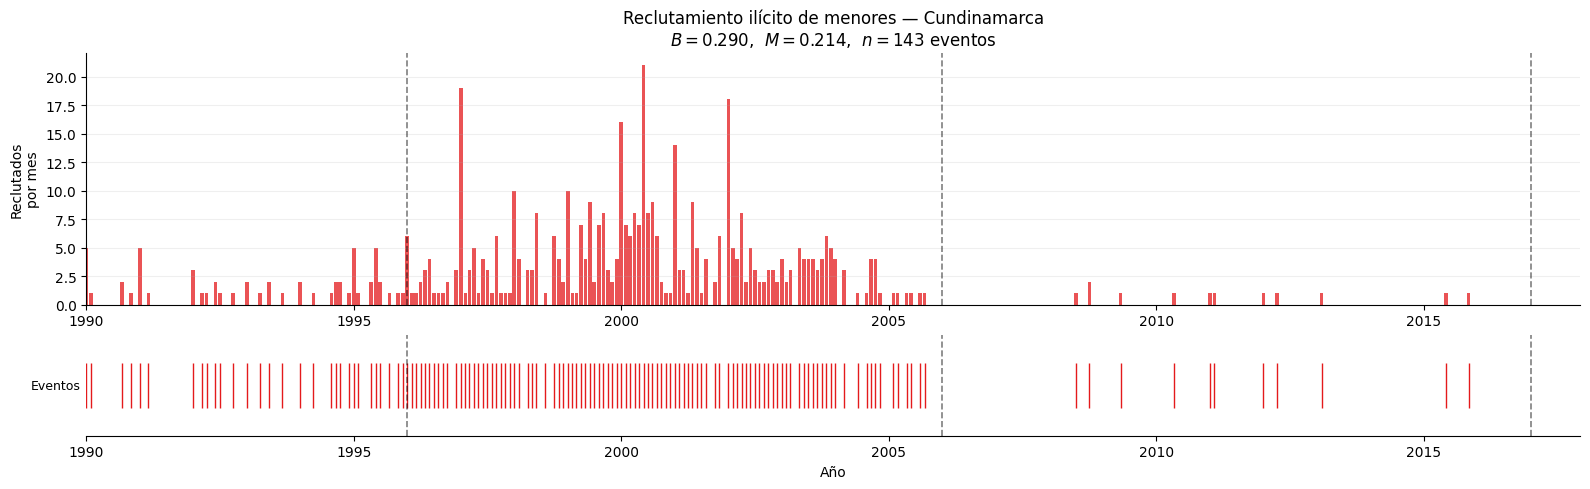

Figura 1 guardada: bt_fig1_serie_raster.png


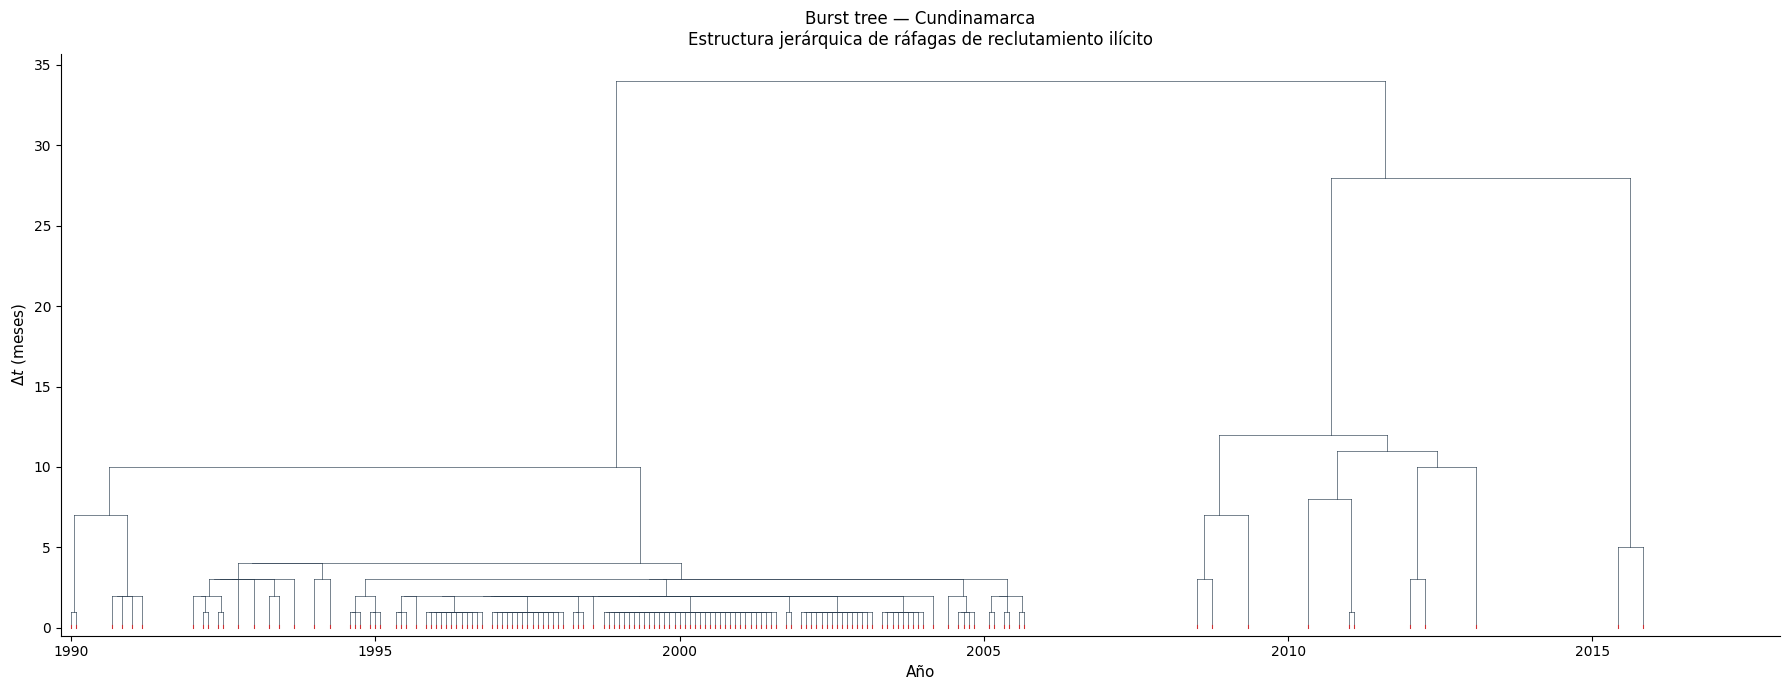

Figura 2 guardada: bt_fig2_burst_tree.png


/tmp/ipykernel_5598/1214597203.py:213: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_hist.legend(fontsize=9, framealpha=0.9)


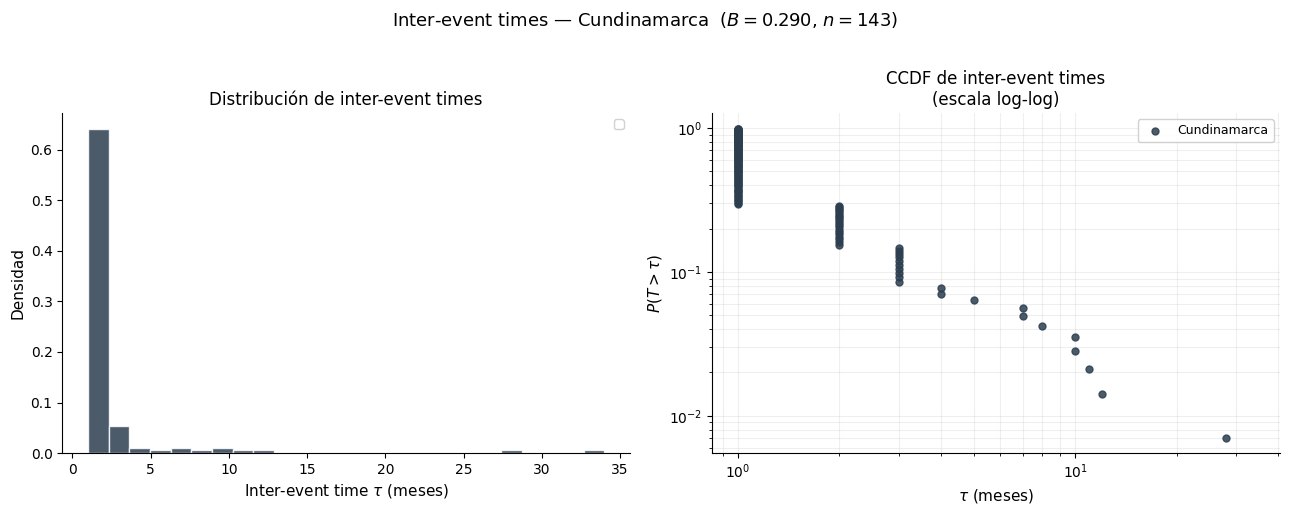

Figura 3 guardada: bt_fig3_iet_distribution.png


In [ ]:
# ============================================================
# BURST TREE — DEPARTAMENTO MÁS BURSTY (GRUPO A)
# Kim & Jo (2016) — Opción A: meses como timestamps
# ============================================================

# --- Identificar departamento ---
dept_top_A = (
    df_resumen[df_resumen['grupo'] == 'A (>100)']
    .sort_values('B', ascending=False)
    .iloc[0]['dept_code']
)
nombre_top_A = str(lookup_nombre.get(dept_top_A, dept_top_A)).title()
B_top_A = df_resumen.loc[df_resumen['dept_code'] == dept_top_A, 'B'].values[0]
M_top_A = df_resumen.loc[df_resumen['dept_code'] == dept_top_A, 'M'].values[0]

print(f"Departamento: {nombre_top_A}")
print(f"B = {B_top_A:.3f}, M = {M_top_A:.3f}")

# --- Extraer serie temporal ---
serie_depto = (
    grilla[grilla['dept_code_hecho'] == dept_top_A]
    .sort_values(['anio', 'mes'])
    .reset_index(drop=True)
)

event_idx    = np.where(serie_depto['reclutados'].values > 0)[0]
event_fechas = serie_depto.loc[event_idx, 'fecha'].values
n_eventos    = len(event_idx)
iets         = np.diff(event_idx).astype(float)

print(f"Eventos      : {n_eventos}")
print(f"IET min/max  : {iets.min():.0f} / {iets.max():.0f} meses")
print(f"IET media    : {iets.mean():.2f} meses")

# ============================================================
# FUNCIÓN: CONSTRUIR BURST TREE
# ============================================================
def construir_burst_tree(event_positions):
    """
    Construye el burst tree por fusiones secuenciales de ráfagas
    adyacentes en orden creciente de IET.
    Retorna lista de merges para visualización.
    """
    n            = len(event_positions)
    next_id      = n
    bursts       = {
        i: {'events': [int(event_positions[i])],
            'center': float(event_positions[i]),
            'height': 0.0}
        for i in range(n)
    }
    active_ids   = list(range(n))
    current_iets = list(np.diff(event_positions).astype(float))
    merges       = []

    while len(active_ids) > 1:
        min_idx  = int(np.argmin(current_iets))
        min_iet  = current_iets[min_idx]
        left_id  = active_ids[min_idx]
        right_id = active_ids[min_idx + 1]
        left     = bursts[left_id]
        right    = bursts[right_id]

        new_events = left['events'] + right['events']
        bursts[next_id] = {
            'events': new_events,
            'center': np.mean(new_events),
            'height': min_iet,
        }
        merges.append({
            'lc': left['center'],  'rc': right['center'],
            'lh': left['height'],  'rh': right['height'],
            'iet': min_iet,
            'left_size': len(left['events']),
            'right_size': len(right['events']),
        })

        active_ids   = (active_ids[:min_idx] +
                        [next_id] +
                        active_ids[min_idx+2:])
        current_iets = (current_iets[:min_idx] +
                        current_iets[min_idx+1:])
        next_id += 1

    return merges

merges = construir_burst_tree(event_idx)
print(f"Fusiones en el burst tree: {len(merges)}")

# Ticks de año para el eje x (índice de mes → año)
años_ticks = range(1990, 2018, 5)
ticks_idx  = [(y - 1990) * 12 for y in años_ticks]

# ============================================================
# FIGURA 1: SERIE TEMPORAL + RASTER PLOT
# ============================================================
fig1, (ax_ts, ax_rast) = plt.subplots(
    2, 1, figsize=(16, 5),
    gridspec_kw={'height_ratios': [2, 0.8]},
    sharex=False
)

# Serie temporal
ax_ts.bar(
    serie_depto['fecha'],
    serie_depto['reclutados'],
    width=25, color='#e41a1c', alpha=0.75, edgecolor='none'
)
for año_corte in [1996, 2006, 2017]:
    ax_ts.axvline(pd.Timestamp(f'{año_corte}-01-01'),
                  color='black', linewidth=1.2,
                  linestyle='--', alpha=0.5)
ax_ts.set_ylabel('Reclutados\npor mes', fontsize=10)
ax_ts.set_title(
    f'Reclutamiento ilícito de menores — {nombre_top_A}\n'
    f'$B={B_top_A:.3f}$,  $M={M_top_A:.3f}$,  '
    f'$n={n_eventos}$ eventos',
    fontsize=12
)
ax_ts.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax_ts.xaxis.set_major_locator(mdates.YearLocator(5))
ax_ts.set_xlim(pd.Timestamp('1990-01-01'), pd.Timestamp('2017-12-01'))
ax_ts.grid(True, alpha=0.2, axis='y')
for spine in ['top', 'right']:
    ax_ts.spines[spine].set_visible(False)

# Raster plot
fechas_num = mdates.date2num(pd.to_datetime(event_fechas))
ax_rast.eventplot(
    fechas_num, orientation='horizontal',
    lineoffsets=0, linelengths=0.7,
    linewidths=1.0, colors='#e41a1c'
)
for año_corte in [1996, 2006, 2017]:
    ax_rast.axvline(
        mdates.date2num(pd.Timestamp(f'{año_corte}-01-01')),
        color='black', linewidth=1.2, linestyle='--', alpha=0.5
    )
ax_rast.set_yticks([])
ax_rast.set_ylabel('Eventos', fontsize=9,
                   rotation=0, ha='right', va='center')
ax_rast.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax_rast.xaxis.set_major_locator(mdates.YearLocator(5))
ax_rast.set_xlim(
    mdates.date2num(pd.Timestamp('1990-01-01')),
    mdates.date2num(pd.Timestamp('2017-12-01'))
)
ax_rast.set_xlabel('Año', fontsize=10)
for spine in ['top', 'right', 'left']:
    ax_rast.spines[spine].set_visible(False)

plt.tight_layout(h_pad=0.5)
plt.savefig('bt_fig1_serie_raster.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figura 1 guardada: bt_fig1_serie_raster.png")

# ============================================================
# FIGURA 2: BURST TREE
# ============================================================
fig2, ax_bt = plt.subplots(figsize=(18, 7))

# Dibujar fusiones
for m in merges:
    ax_bt.plot([m['lc'], m['lc']], [m['lh'], m['iet']],
               color='#2c3e50', linewidth=0.6, alpha=0.75)
    ax_bt.plot([m['rc'], m['rc']], [m['rh'], m['iet']],
               color='#2c3e50', linewidth=0.6, alpha=0.75)
    ax_bt.plot([m['lc'], m['rc']], [m['iet'], m['iet']],
               color='#2c3e50', linewidth=0.6, alpha=0.75)

# Eventos en la base
for pos in event_idx:
    ax_bt.plot([pos, pos], [0, 0.15],
               color='#e41a1c', linewidth=0.8, alpha=0.8)

ax_bt.set_xlim(-2, 337)
ax_bt.set_ylim(-0.5, iets.max() * 1.05)
ax_bt.set_xticks(ticks_idx)
ax_bt.set_xticklabels([str(y) for y in años_ticks])
ax_bt.set_xlabel('Año', fontsize=11)
ax_bt.set_ylabel('$\\Delta t$ (meses)', fontsize=11)
ax_bt.set_title(
    f'Burst tree — {nombre_top_A}\n'
    f'Estructura jerárquica de ráfagas de reclutamiento ilícito',
    fontsize=12
)
for spine in ['top', 'right']:
    ax_bt.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig('bt_fig2_burst_tree.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figura 2 guardada: bt_fig2_burst_tree.png")

# ============================================================
# FIGURA 3: DISTRIBUCIÓN DE IETs (histograma + CCDF)
# ============================================================
fig3, (ax_hist, ax_ccdf) = plt.subplots(1, 2, figsize=(13, 5))

# Histograma
ax_hist.hist(iets, color='#2c3e50',
             edgecolor='white', alpha=0.85, density=True)

# Curva exponencial de referencia (tasa = 1/mu)
# tau_ref  = np.linspace(0.5, iets.max(), 300)
# exp_ref  = (1 / iets.mean()) * np.exp(-tau_ref / iets.mean())
# ax_hist.plot(tau_ref, exp_ref, color='#e41a1c', linewidth=2,
#              linestyle='--', alpha=0.8,
#              label=f'Exponencial ref.\n($\\mu={iets.mean():.1f}$ meses)')
ax_hist.set_xlabel('Inter-event time $\\tau$ (meses)', fontsize=11)
ax_hist.set_ylabel('Densidad', fontsize=11)
ax_hist.set_title('Distribución de inter-event times', fontsize=12)
ax_hist.legend(fontsize=9, framealpha=0.9)
for spine in ['top', 'right']:
    ax_hist.spines[spine].set_visible(False)

# CCDF en log-log
iet_sorted = np.sort(iets)
ccdf       = 1 - np.arange(1, len(iet_sorted) + 1) / len(iet_sorted)
ax_ccdf.scatter(iet_sorted, ccdf, s=25, color='#2c3e50',
                alpha=0.85, zorder=3, label=nombre_top_A)

# ccdf_exp = np.exp(-iet_sorted / iets.mean())
# ax_ccdf.plot(iet_sorted, ccdf_exp, color='#e41a1c', linewidth=2,
#              linestyle='--', alpha=0.8,
#              label=f'Exponencial ref.\n($\\mu={iets.mean():.1f}$ meses)')

ax_ccdf.set_xscale('log')
ax_ccdf.set_yscale('log')
ax_ccdf.set_xlabel('$\\tau$ (meses)', fontsize=11)
ax_ccdf.set_ylabel('$P(T > \\tau)$', fontsize=11)
ax_ccdf.set_title('CCDF de inter-event times\n(escala log-log)', fontsize=12)
ax_ccdf.legend(fontsize=9, framealpha=0.9)
ax_ccdf.grid(True, alpha=0.2, which='both')
for spine in ['top', 'right']:
    ax_ccdf.spines[spine].set_visible(False)

plt.suptitle(
    f'Inter-event times — {nombre_top_A}  '
    f'($B={B_top_A:.3f}$, $n={n_eventos}$)',
    fontsize=13, y=1.02
)
plt.tight_layout()
plt.savefig('bt_fig3_iet_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figura 3 guardada: bt_fig3_iet_distribution.png")

In [ ]:
# Acuerdo de paz entre las FARC y gobierno, acuerdo de desmovilización con las AUC, bajas de cabecillas importantes